# 08 学習済み Fashion-MNIST MLP：第1 Linear の TT-rank sweep

07までで、小さいweightに対する3-core TT-rank sweepは確認済みです。ここからは理論の復習ではなく、**学習済みFashion-MNIST MLPへTT圧縮を適用する実装**へ進みます。

学習済みbaselineの`fc1`だけを3-core TTLinearへ置換し、weight誤差、parameter数、validation accuracy、prediction agreement、logits RMSE、Pareto frontierをrankごとに評価します。

主要な実装部分には **TODO と `_____`** を残しています。別セルに解答は置きません。test評価、fine-tuning、`fc2`のTT化、tensorization比較は次以降へ残します。

実装を終えたら`EXERCISES_COMPLETED = True`へ変更してRestart Kernel → Run Allしてください。`False`の間はTODO依存部分だけをスキップします。


In [100]:
# ============================================================
# import とプロジェクトルートの解決
# ============================================================
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
import torch.nn.functional as F
from IPython.display import display
from sklearn.preprocessing import MinMaxScaler
from torch.utils.data import DataLoader

for candidate in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    src_dir = candidate / "src"
    if (src_dir / "nn_compression").is_dir():
        if str(src_dir) not in sys.path:
            sys.path.insert(0, str(src_dir))
        break
else:
    raise RuntimeError("src/nn_compression が見つかりません。")

from nn_compression.compression import (
    TTLinear,
    factorize_named_tt_linear,
    tt_matrix_ranks,
    tt_matrix_to_dense,
)
from nn_compression.datasets import (
    get_fashion_mnist_datasets,
    make_fashion_mnist_loaders,
    split_fashion_mnist_dataset,
)
from nn_compression.metrics import (
    accuracy_drop,
    count_parameters,
    relative_frobenius_error,
)
from nn_compression.models import MNISTMLP
from nn_compression.selection import (
    extract_pareto_frontier,
    find_knee_point,
    get_first_point,
    line_equation,
)
from nn_compression.utils import find_project_root, make_torch_generator, set_seed


In [101]:
SEED = 0
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DTYPE = torch.float32
TARGET_LAYER = "fc1"
OUT_MODES = (2, 8, 32)
IN_MODES = (49, 8, 2)
RANK_CANDIDATES = [1, 2, 4, 8, 16, 32, 64]
RANK_VALIDATION_BATCH_SIZE = 512
SAVE_RESULTS = True

# TODOをすべて実装し終えたらTrueへ変更する。
EXERCISES_COMPLETED = True

set_seed(SEED)
project_root = find_project_root(Path.cwd())
data_dir = project_root / "data"
checkpoint_path = (
    project_root / "models" / "10_svd" / "20_fashion_mnist_mlp"
    / "03_mlp_svd_finetuning_using_src_corrected_rerun"
    / "baseline_same_run.pt"
)
results_dir = (
    project_root / "results" / "30_tt_mps" / "10_fashion_mnist_mlp"
    / "08_pretrained_mlp_fc1_tt_rank_sweep"
)

assert math.prod(OUT_MODES) == 512
assert math.prod(IN_MODES) == 784
assert checkpoint_path.is_file(), checkpoint_path
print("device:", DEVICE)
print("physical sizes:", tuple(m * n for m, n in zip(OUT_MODES, IN_MODES)))
print("rank candidates:", RANK_CANDIDATES)
print("exercises completed:", EXERCISES_COMPLETED)


device: cuda
physical sizes: (98, 64, 64)
rank candidates: [1, 2, 4, 8, 16, 32, 64]
exercises completed: True


## 1. Rank選択用validationの再構成

checkpoint作成時と同じseedで、Fashion-MNISTの学習用60,000件を50,000 / 5,000 / 5,000へ分割します。今回使うのは3番目のrank選択用5,000件です。test setはrank選択に使いません。

データ分割は実験条件の再現なので、ここは完成コードです。


In [102]:
full_train_dataset, test_dataset = get_fashion_mnist_datasets(data_dir, download=True)
train_dataset, early_stopping_dataset, rank_validation_dataset = (
    split_fashion_mnist_dataset(
        full_train_dataset,
        (50_000, 5_000, 5_000),
        seed=SEED,
    )
)
loaders = make_fashion_mnist_loaders(
    train_dataset,
    early_stopping_dataset,
    test_dataset,
    train_batch_size=64,
    validation_batch_size=RANK_VALIDATION_BATCH_SIZE,
    test_batch_size=1000,
    rank_validation_dataset=rank_validation_dataset,
    train_generator=make_torch_generator(SEED),
)
rank_validation_loader = loaders["validation_loader_rank"]
assert len(rank_validation_loader.dataset) == 5_000
print("rank-selection validation size:", len(rank_validation_loader.dataset))
print("test size (not used):", len(test_dataset))


rank-selection validation size: 5000
test size (not used): 10000


## 2. TODO 1：baseline checkpointを読み込む

### このセルで確認すること

`MNISTMLP`を指定dtype・deviceで生成し、state dictを読み込み、evaluation modeへ切り替えます。

### 期待する検証結果

- `fc1.weight.shape == (512, 784)`
- validation logits shapeが `(5000, 10)`

ヒント：`torch.load(..., weights_only=True)`、`load_state_dict(...)`、`eval()`を使います。


In [103]:
def load_baseline_model(
    checkpoint: Path,
    *,
    device: torch.device,
    dtype: torch.dtype,
) -> MNISTMLP:
    """学習済みbaselineを読み込み、評価モードで返す。

    Args:
        checkpoint: 読み込むbaselineのstate dictが保存されたファイルパス。
        device: モデルとcheckpoint内のtensorを配置する計算device。
        dtype: モデルparameterに使用する浮動小数点dtype。

    Returns:
        checkpointのparameterを読み込み、evaluation modeにしたMNISTMLP。
    """
    # TODO 1-1: モデルを生成し、device / dtypeを揃える。
    model = MNISTMLP().to(device=device, dtype=dtype)

    # TODO 1-2: state dictだけを安全に読み込む。
    state_dict = torch.load(
        checkpoint,
        map_location=device,
        weights_only=True,
    )

    # TODO 1-3: state dictをモデルへ設定する。
    model.load_state_dict(state_dict)
    
    # TODO 1-4: evaluation modeへ切り替える。
    model.eval()
    
    return model


## 3. TODO 2：validation全体のlogitsと分類指標を集める

同じsample順でdense modelとTT modelを比較できるよう、logitsとlabelをCPUへ集めます。評価時には勾配を作りません。

$$
\text{accuracy}=\frac{\text{correct predictions}}{\text{number of samples}}.
$$

期待する結果は、logitsが2階、labelsが1階、sample数が一致し、accuracyが0以上1以下になることです。


In [104]:
def collect_logits_and_labels(
    model: torch.nn.Module,
    loader: DataLoader,
    *,
    device: torch.device,
) -> tuple[torch.Tensor, torch.Tensor]:
    """loader全体のlogitsとlabelを、順序を保ってCPUへ集める。

    Args:
        model: 各画像batchからlogitsを計算する評価対象モデル。
        loader: 評価用の画像と正解labelをbatch単位で供給するDataLoader。
        device: forward時に画像を配置する計算device。

    Returns:
        CPU上へ集約したlogitsとlabelsの組。shapeはそれぞれ
        ``(sample数, class数)`` と ``(sample数,)``。
    """
    model.eval()
    logits_batches = []
    label_batches = []

    # TODO 2-1: 評価時に勾配を作らないcontextを指定する。
    with torch.no_grad():
        for images, labels in loader:
            # TODO 2-2: 画像を評価deviceへ移す。
            images = images.to(device=device)
            # TODO 2-3: forward結果をCPUへ移して保存する。
            logits_batches.append(model(images).cpu())
            label_batches.append(labels.cpu())

    if not logits_batches:
        raise ValueError("空のDataLoaderは評価できません。")

    # TODO 2-4: batch列をsample軸方向へ結合する。
    logits = torch.cat(logits_batches, dim=0)
    labels = torch.cat(label_batches, dim=0)
    return logits, labels


def classification_summary(
    logits: torch.Tensor,
    labels: torch.Tensor,
) -> dict[str, float]:
    """平均cross-entropy lossとaccuracyを計算する。

    Args:
        logits: 各sample・各classの未正規化score。shapeは
            ``(sample数, class数)``。
        labels: 各sampleの正解class index。shapeは ``(sample数,)``。

    Returns:
        ``loss``と``accuracy``をPython floatで保持する辞書。
    """
    # TODO 2-5: lossとaccuracyをPython floatで返す。
    loss = F.cross_entropy(logits, labels).item()
    predictions = logits.argmax(dim=1)
    accuracy = (predictions == labels).float().mean().item()
    return {"loss": loss, "accuracy": accuracy}


## 4. 既存APIで`fc1`だけをTTLinearへ置換する

baseline modelを変更せず、コピー側の`fc1`だけをTTLinearへ置換します。tensorizationは

$$
(m_1,m_2,m_3)=(2,8,32),\qquad(n_1,n_2,n_3)=(49,8,2)
$$

で固定します。dense側が`nn.Linear`のまま、compressed側だけが`TTLinear`になり、`fc2`と`fc3`は変化しないことを確認します。

置換処理は`src`にある`factorize_named_tt_linear`をrank sweep内で直接呼び出します。同じ処理を行うNotebook独自のwrapper関数は作りません。


In [105]:
# 置換にはimport済みのfactorize_named_tt_linearを直接使う。
# 引数の意味は次のrank sweepセルで確認する。


## 5. TODO 4：weight誤差とlogits誤差を計算する

実装する指標は次です。

$$
E_F(r)=\|W_1-\widetilde W_1(r)\|_F,\qquad E_2(r)=\|W_1-\widetilde W_1(r)\|_2,
$$

$$
\operatorname{RMSE}_{logits}=\sqrt{\operatorname{mean}((\widetilde L-L)^2)}.
$$

prediction agreementはdense predictionとTT predictionが一致した割合であり、ground-truth accuracyとは別の指標です。すべての誤差が非負、agreementが0以上1以下になることを確認します。


In [106]:
# 先頭セルにも一部あり。このセルで使う compression API。
from nn_compression.compression import (
    tt_matrix_num_parameters,
    tt_matrix_ranks,
    tt_matrix_to_dense,
)


def tt_weight_summary(
    dense_layer: torch.nn.Linear,
    tt_layer: TTLinear,
) -> dict[str, tuple[int, ...] | int | float]:
    """TTLinearのdense reconstructionとweight誤差を集計する。

    Args:
        dense_layer: 比較基準となる学習済みdense Linear層。
        tt_layer: ``dense_layer``をTT分解して得た比較対象のTTLinear層。

    Returns:
        actual TT-rank、parameter数、圧縮率、Frobenius誤差、
        spectral誤差と、それぞれの相対誤差を保持する辞書。
    """
    with torch.no_grad():
        # TODO 4-1: TT coresからdense weightを再構成する。
        reconstructed_weight = tt_matrix_to_dense(
            list(tt_layer.cores),   # TTLinear の cores
            tt_layer.out_modes,     # または引数の out_modes
            tt_layer.in_modes,      # または引数の in_modes
        )
        # TODO 4-2: denseとの差分を作る。
        delta_weight = dense_layer.weight - reconstructed_weight
        # TODO 4-3: Frobenius / spectral normを計算する。
        frobenius_error = torch.linalg.matrix_norm(delta_weight, ord="fro")
        spectral_error = torch.linalg.matrix_norm(delta_weight, ord=2)
        dense_spectral = torch.linalg.matrix_norm(dense_layer.weight, ord=2)

    # TODO 4-4: TT coresとbiasの保存要素数を数える。
    tt_layer_parameters = tt_matrix_num_parameters(list(tt_layer.cores))
    if tt_layer.bias is not None:
        tt_layer_parameters += tt_layer.bias.numel()
    dense_layer_parameters = dense_layer.weight.numel()
    if dense_layer.bias is not None:
        dense_layer_parameters += dense_layer.bias.numel()

    return {
        "actual_ranks": tt_matrix_ranks(list(tt_layer.cores)),
        "fc1_parameters": int(tt_layer_parameters),
        "fc1_compression_ratio": dense_layer_parameters / tt_layer_parameters,
        "weight_frobenius_error": float(frobenius_error),
        "weight_relative_frobenius_error": float(
            relative_frobenius_error(
                dense_layer.weight.detach(),
                reconstructed_weight.detach(),
            )
        ),
        "weight_spectral_error": float(spectral_error),
        "weight_relative_spectral_error": float(spectral_error / dense_spectral),
    }


def compare_logits(
    reference_logits: torch.Tensor,
    compressed_logits: torch.Tensor,
) -> dict[str, float]:
    """dense logitsに対するagreementとlogits誤差を返す。

    Args:
        reference_logits: dense baselineが出力した比較基準のlogits。
        compressed_logits: 同じsample順でTT圧縮モデルが出力したlogits。

    Returns:
        prediction agreement、logits RMSE、最大絶対誤差を保持する辞書。
    """
    # TODO 4-5: logits差分を作る。
    difference = compressed_logits - reference_logits
    # TODO 4-6: argmax predictionの一致率を計算する。
    # 各画像について、最大スコアのクラス番号を取り出す。
    reference_predictions = reference_logits.argmax(dim=1)
    compressed_predictions = compressed_logits.argmax(dim=1)
    agreement = (reference_predictions == compressed_predictions).float().mean().item()
    return {
        "prediction_agreement": agreement,
        # TODO 4-7: RMSEと最大絶対誤差を計算する。
        "logits_rmse": float(torch.sqrt(torch.mean(difference ** 2))),
        "logits_max_abs_error": float(difference.abs().max()),
    }


## 6. TODO 5：学習済みMLP上でrank sweepする

baseline logitsは1回だけ計算します。各rankについて新しい圧縮モデルを作り、同じrank-selection validationに対する指標を`record`へまとめます。

期待する結果は、record数がrank候補数と一致し、requested rankとactual ranksが別々に記録され、sweep後もbaselineの`fc1.weight`が変化しないことです。accuracyの単調性は仮定しません。


In [107]:
if EXERCISES_COMPLETED:
    # TODO 5-1: baselineを読み込み、比較用weightを保存する。
    baseline_model = load_baseline_model(
        checkpoint_path, device=DEVICE, dtype=DTYPE
    )
    baseline_fc1_weight_before = baseline_model.fc1.weight.detach().clone()

    # TODO 5-2: baseline logits / labelsとbaseline指標を計算する。
    # parameter数には既存APIのcount_parametersを使う。
    baseline_logits, rank_validation_labels = collect_logits_and_labels(
        baseline_model, rank_validation_loader, device=DEVICE
    )
    baseline_summary = classification_summary(
        baseline_logits, rank_validation_labels
    )
    baseline_parameters = count_parameters(baseline_model)

    assert baseline_model.fc1.weight.shape == (512, 784)
    assert baseline_logits.shape == (5_000, 10)
    assert rank_validation_labels.shape == (5_000,)

    rank_records = []
    for requested_rank in RANK_CANDIDATES:
        # TODO 5-3: 既存APIのfactorize_named_tt_linearを直接使い、
        # requested rankでfc1だけをTT化する。
        compressed_model = factorize_named_tt_linear(
            baseline_model,
            "fc1",
            OUT_MODES,
            IN_MODES,
            max_rank=requested_rank,
        )
        compressed_logits, compressed_labels = collect_logits_and_labels(
            compressed_model, rank_validation_loader, device=DEVICE
        )
        assert torch.equal(compressed_labels, rank_validation_labels)

        # TODO 5-5: 分類・weight・logitsの指標を計算する。
        validation_summary = classification_summary(
            compressed_logits, compressed_labels
        )
        weight_summary = tt_weight_summary(
            baseline_model.fc1, compressed_model.fc1
        )
        logits_summary = compare_logits(
            baseline_logits, compressed_logits
        )
        # model全体のparameter数には既存APIのcount_parametersを使う。
        model_parameters = count_parameters(compressed_model)

        record = {
            "requested_rank": requested_rank,
            **weight_summary,
            "model_parameters": model_parameters,
            # TODO 5-6: model全体のcompression ratioを計算する。
            "model_compression_ratio": baseline_parameters/model_parameters,
            "validation_loss": validation_summary["loss"],
            "validation_accuracy": validation_summary["accuracy"],
            # TODO 5-7: 既存APIのaccuracy_dropを使って、
            # baselineからのaccuracy dropを計算する。
            "accuracy_drop": accuracy_drop(
                baseline_summary["accuracy"],
                validation_summary["accuracy"],
                verbose=False,  # sweep中はログがうるさいので切るとよい
            ),
            **logits_summary,
        }
        rank_records.append(record)
        print(
            f"rank={requested_rank:>2d} actual={record['actual_ranks']} | "
            f"params={model_parameters:>7,d} "
            f"acc={record['validation_accuracy']:.4f} "
            f"agreement={record['prediction_agreement']:.4f}"
        )
        del compressed_model, compressed_logits, compressed_labels
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()

    assert torch.equal(baseline_model.fc1.weight, baseline_fc1_weight_before)
    df_rank_sweep = pd.DataFrame(rank_records)
    display(df_rank_sweep.round(6))
else:
    print("TODO 1〜5の実装後、EXERCISES_COMPLETED=Trueにしてください。")


rank= 1 actual=(1, 1, 1, 1) | params=134,636 acc=0.1050 agreement=0.1166
rank= 2 actual=(1, 2, 2, 1) | params=134,990 acc=0.1050 agreement=0.1166
rank= 4 actual=(1, 4, 4, 1) | params=136,082 acc=0.1814 agreement=0.1928
rank= 8 actual=(1, 8, 8, 1) | params=139,802 acc=0.2054 agreement=0.2100
rank=16 actual=(1, 16, 16, 1) | params=153,386 acc=0.3978 agreement=0.3990
rank=32 actual=(1, 32, 32, 1) | params=205,130 acc=0.7556 agreement=0.7976
rank=64 actual=(1, 64, 64, 1) | params=406,922 acc=0.8736 agreement=0.9558


,requested_rank,actual_ranks,fc1_parameters,fc1_compression_ratio,weight_frobenius_error,weight_relative_frobenius_error,weight_spectral_error,weight_relative_spectral_error,model_parameters,model_compression_ratio,validation_loss,validation_accuracy,accuracy_drop,prediction_agreement,logits_rmse,logits_max_abs_error
0,1,"(1, 1, 1, 1)",738,544.607046,46.632633,0.986781,13.083858,0.994424,134636,3.979753,2.483855,0.1050,0.7834,0.1166,9.728988,67.860802
1,2,"(1, 2, 2, 1)",1092,368.058608,46.475658,0.983459,12.957272,0.984803,134990,3.969316,2.506873,0.1050,0.7834,0.1166,9.732499,67.835449
2,4,"(1, 4, 4, 1)",2184,184.029304,46.042782,0.974299,12.651652,0.961575,136082,3.937464,2.378732,0.1814,0.7070,0.1928,9.699929,67.504417
3,8,"(1, 8, 8, 1)",5904,68.075881,44.802044,0.948044,11.387644,0.865505,139802,3.832692,2.324727,0.2054,0.6830,0.2100,9.641007,66.672394
4,16,"(1, 16, 16, 1)",19488,20.623974,41.455433,0.877227,9.653074,0.733671,153386,3.493265,1.871743,0.3978,0.4906,0.3990,8.465771,57.759239
5,32,"(1, 32, 32, 1)",71232,5.642408,33.437206,0.707556,7.497622,0.569849,205130,2.612090,0.699736,0.7556,0.1328,0.7976,5.978705,33.925205
6,64,"(1, 64, 64, 1)",273024,1.472105,17.869102,0.378123,3.885029,0.295277,406922,1.316758,0.346136,0.8736,0.0148,0.9558,1.586787,13.134895


## 7. Pareto frontierとknee近傍を自動選択する

parameter数は小さい方、validation accuracyは大きい方を良いとします。`src`の`extract_pareto_frontier`は両目的を最小化するAPIなので、accuracyをvalidation errorへ変換してから呼び出します。

Pareto点についてparameter数とvalidation errorを0〜1へ正規化し、両端を結ぶ直線から最も遠い点をkneeとします。次Notebookへ渡す候補は、parameter数順でknee、その1つ前、その1つ後です。Pareto・kneeの計算は既存APIを再利用し、このセルは完成コードとします。


In [108]:
if EXERCISES_COMPLETED:
    # accuracy最大化を、既存Pareto APIが扱う最小化目的へ変換する。
    pareto_input = df_rank_sweep.copy()
    pareto_input["validation_error"] = (
        1.0 - pareto_input["validation_accuracy"]
    )
    df_pareto_with_objective = extract_pareto_frontier(
        pareto_input,
        x_column="model_parameters",
        y_column="validation_error",
    ).sort_values("model_parameters").reset_index(drop=True)
    if len(df_pareto_with_objective) < 2:
        raise ValueError("knee選択には2点以上のPareto点が必要です。")

    # 軸スケールの違いでknee距離が偏らないよう、両目的を0〜1へ揃える。
    selection_frame = df_pareto_with_objective.copy()
    scaler = MinMaxScaler()
    selection_frame[[
        "model_parameters_normalized",
        "validation_error_normalized",
    ]] = scaler.fit_transform(
        selection_frame[["model_parameters", "validation_error"]]
    )

    # 正規化Pareto frontierの両端を結ぶ直線からkneeを求める。
    left_endpoint = get_first_point(
        selection_frame,
        "model_parameters_normalized",
        "model_parameters_normalized",
        "validation_error_normalized",
    )
    right_endpoint = get_first_point(
        selection_frame,
        "validation_error_normalized",
        "model_parameters_normalized",
        "validation_error_normalized",
    )
    knee_point, knee_distance = find_knee_point(
        selection_frame,
        *line_equation(left_endpoint, right_endpoint),
        "model_parameters_normalized",
        "validation_error_normalized",
    )
    knee_mask = (
        (
            selection_frame["model_parameters_normalized"]
            == knee_point[0]
        )
        & (
            selection_frame["validation_error_normalized"]
            == knee_point[1]
        )
    )
    knee_position = int(selection_frame.index[knee_mask][0])

    # parameter数順でkneeの前後1点を含む2〜3候補を選ぶ。
    first_position = max(knee_position - 1, 0)
    last_position = min(knee_position + 1, len(selection_frame) - 1)
    selected_rank_candidates = selection_frame.iloc[
        first_position : last_position + 1
    ].copy()
    selected_positions = range(first_position, last_position + 1)
    selected_rank_candidates["selection_role"] = [
        "aggressive"
        if position < knee_position
        else "balanced"
        if position == knee_position
        else "conservative"
        for position in selected_positions
    ]
    selected_ranks_for_next = (
        selected_rank_candidates["requested_rank"].astype(int).tolist()
    )

    assert 2 <= len(selected_ranks_for_next) <= 3
    assert len(selected_ranks_for_next) == len(set(selected_ranks_for_next))
    assert (
        selected_rank_candidates["selection_role"] == "balanced"
    ).sum() == 1

    # 可視化と保存では、実験指標だけを持つ従来のPareto表を使う。
    df_pareto = df_pareto_with_objective.drop(columns="validation_error")
    print("Pareto frontier rows:", len(df_pareto))
    print("knee distance:", round(knee_distance, 6))
    print("selected ranks for next notebook:", selected_ranks_for_next)
    display(
        selected_rank_candidates[[
            "selection_role",
            "requested_rank",
            "model_parameters",
            "model_compression_ratio",
            "validation_accuracy",
            "prediction_agreement",
        ]].round(6)
    )
else:
    print("Pareto・knee選択はrank sweep実装後に実行します。")


Pareto frontier rows: 6
knee distance: 0.41548
selected ranks for next notebook: [16, 32, 64]


,selection_role,requested_rank,model_parameters,model_compression_ratio,validation_accuracy,prediction_agreement
3,aggressive,16,153386,3.493265,0.3978,0.3990
4,balanced,32,205130,2.612090,0.7556,0.7976
5,conservative,64,406922,1.316758,0.8736,0.9558


## 8. 穴埋め後の数値検証と可視化

TODOを実装して`EXERCISES_COMPLETED=True`にすると、parameter数、compression ratio、accuracy、agreement、actual ranksを検証し、rank trade-offとPareto frontierを描きます。


,requested_rank,actual_ranks,fc1_parameters,fc1_compression_ratio,weight_frobenius_error,weight_relative_frobenius_error,weight_spectral_error,weight_relative_spectral_error,model_parameters,model_compression_ratio,validation_loss,validation_accuracy,accuracy_drop,prediction_agreement,logits_rmse,logits_max_abs_error
0,1,"(1, 1, 1, 1)",738,544.607046,46.632633,0.986781,13.083858,0.994424,134636,3.979753,2.483855,0.1050,0.7834,0.1166,9.728988,67.860802
1,4,"(1, 4, 4, 1)",2184,184.029304,46.042782,0.974299,12.651652,0.961575,136082,3.937464,2.378732,0.1814,0.7070,0.1928,9.699929,67.504417
2,8,"(1, 8, 8, 1)",5904,68.075881,44.802044,0.948044,11.387644,0.865505,139802,3.832692,2.324727,0.2054,0.6830,0.2100,9.641007,66.672394
3,16,"(1, 16, 16, 1)",19488,20.623974,41.455433,0.877227,9.653074,0.733671,153386,3.493265,1.871743,0.3978,0.4906,0.3990,8.465771,57.759239
4,32,"(1, 32, 32, 1)",71232,5.642408,33.437206,0.707556,7.497622,0.569849,205130,2.612090,0.699736,0.7556,0.1328,0.7976,5.978705,33.925205
5,64,"(1, 64, 64, 1)",273024,1.472105,17.869102,0.378123,3.885029,0.295277,406922,1.316758,0.346136,0.8736,0.0148,0.9558,1.586787,13.134895


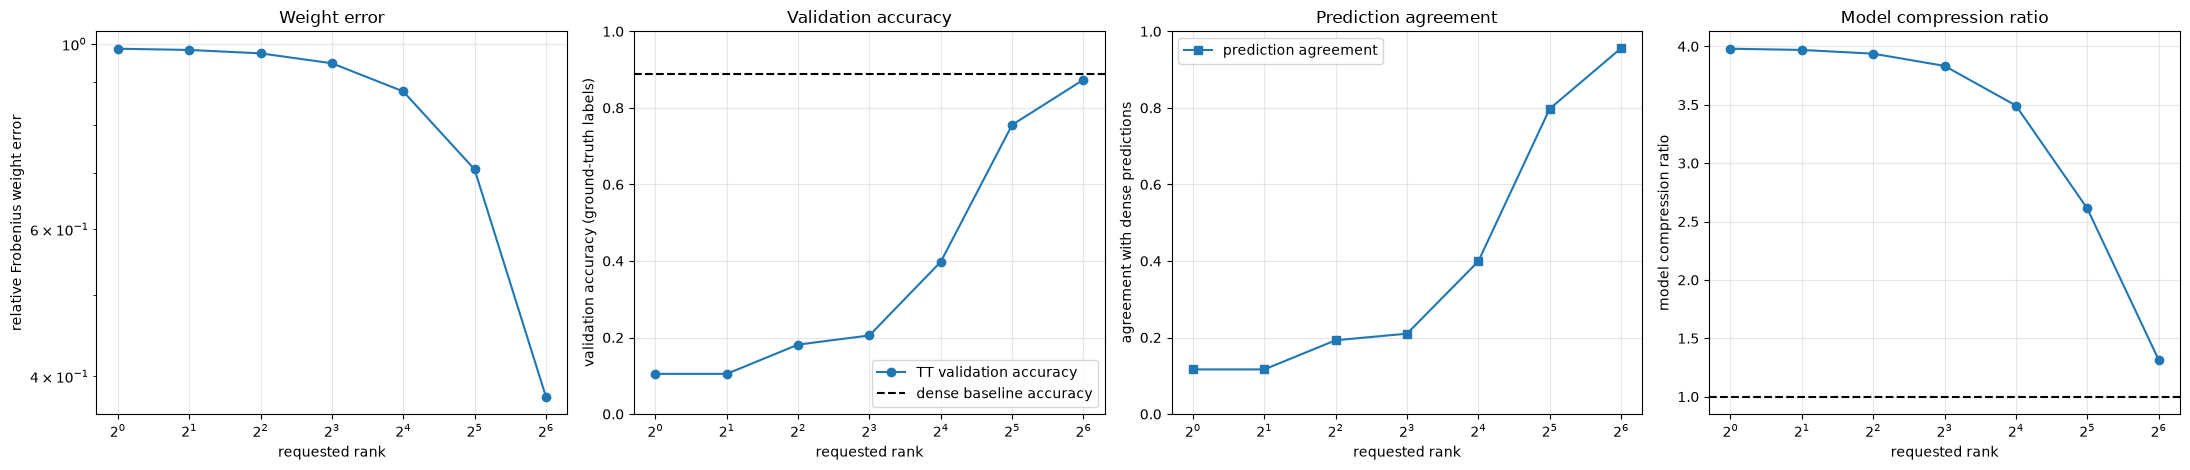

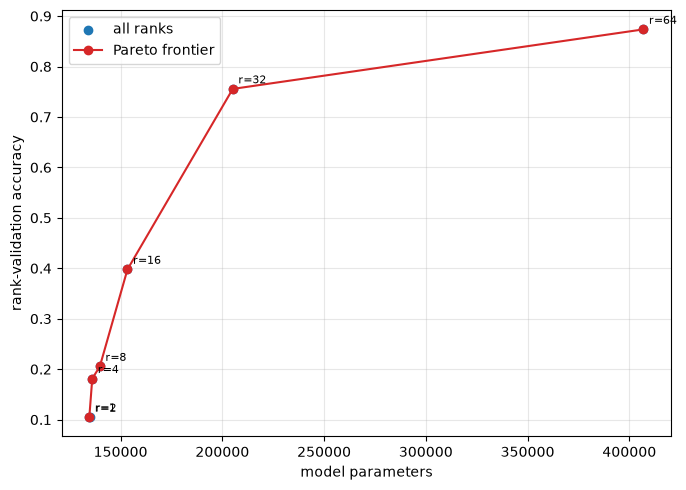

sanity checks: OK


In [109]:
if EXERCISES_COMPLETED:
    assert df_rank_sweep["requested_rank"].tolist() == RANK_CANDIDATES
    assert df_rank_sweep["model_parameters"].is_monotonic_increasing
    assert df_rank_sweep["fc1_parameters"].is_monotonic_increasing
    assert df_rank_sweep["model_compression_ratio"].is_monotonic_decreasing
    assert df_rank_sweep["validation_accuracy"].between(0.0, 1.0).all()
    assert df_rank_sweep["prediction_agreement"].between(0.0, 1.0).all()
    assert (df_rank_sweep["weight_relative_frobenius_error"] >= 0.0).all()
    assert (df_rank_sweep["logits_rmse"] >= 0.0).all()

    for requested_rank, actual_ranks in zip(
        df_rank_sweep["requested_rank"], df_rank_sweep["actual_ranks"]
    ):
        assert actual_ranks[0] == 1 and actual_ranks[-1] == 1
        assert all(rank <= requested_rank for rank in actual_ranks[1:-1])

    display(df_pareto.round(6))

    fig, axes = plt.subplots(1, 4, figsize=(22, 4.8))

    # 1. TT-rankに対するweight近似誤差。
    axes[0].plot(
        df_rank_sweep["requested_rank"],
        df_rank_sweep["weight_relative_frobenius_error"],
        marker="o",
    )
    axes[0].set_xscale("log", base=2)
    axes[0].set_yscale("log")
    axes[0].set_xlabel("requested rank")
    axes[0].set_ylabel("relative Frobenius weight error")
    axes[0].set_title("Weight error")
    axes[0].grid(True, alpha=0.3)

    # 2. 正解labelを基準とするvalidation accuracy。
    axes[1].plot(
        df_rank_sweep["requested_rank"],
        df_rank_sweep["validation_accuracy"],
        marker="o", label="TT validation accuracy",
    )
    axes[1].axhline(
        baseline_summary["accuracy"], color="black", linestyle="--",
        label="dense baseline accuracy",
    )
    axes[1].set_xscale("log", base=2)
    axes[1].set_xlabel("requested rank")
    axes[1].set_ylabel("validation accuracy (ground-truth labels)")
    axes[1].set_ylim(0.0, 1.0)
    axes[1].set_title("Validation accuracy")
    axes[1].grid(True, alpha=0.3)
    axes[1].legend()

    # 3. Dense baselineの予測を基準とするprediction agreement。
    axes[2].plot(
        df_rank_sweep["requested_rank"],
        df_rank_sweep["prediction_agreement"],
        marker="s", label="prediction agreement",
    )
    axes[2].set_xscale("log", base=2)
    axes[2].set_xlabel("requested rank")
    axes[2].set_ylabel("agreement with dense predictions")
    axes[2].set_ylim(0.0, 1.0)
    axes[2].set_title("Prediction agreement")
    axes[2].grid(True, alpha=0.3)
    axes[2].legend()

    # 4. Dense modelに対するmodel全体の圧縮率。
    axes[3].plot(
        df_rank_sweep["requested_rank"],
        df_rank_sweep["model_compression_ratio"],
        marker="o",
    )
    axes[3].axhline(1.0, color="black", linestyle="--")
    axes[3].set_xscale("log", base=2)
    axes[3].set_xlabel("requested rank")
    axes[3].set_ylabel("model compression ratio")
    axes[3].set_title("Model compression ratio")
    axes[3].grid(True, alpha=0.3)
    fig.tight_layout()
    plt.show()

    fig_pareto, ax = plt.subplots(figsize=(7, 5))
    ax.scatter(
        df_rank_sweep["model_parameters"],
        df_rank_sweep["validation_accuracy"],
        label="all ranks",
    )
    ax.plot(
        df_pareto["model_parameters"],
        df_pareto["validation_accuracy"],
        marker="o", color="tab:red", label="Pareto frontier",
    )
    for _, row in df_rank_sweep.iterrows():
        ax.annotate(
            f"r={int(row['requested_rank'])}",
            (row["model_parameters"], row["validation_accuracy"]),
            xytext=(4, 4), textcoords="offset points", fontsize=8,
        )
    ax.set_xlabel("model parameters")
    ax.set_ylabel("rank-validation accuracy")
    ax.grid(True, alpha=0.3)
    ax.legend()
    fig_pareto.tight_layout()
    plt.show()
    print("sanity checks: OK")
else:
    print("数値検証と可視化はTODO実装後に実行します。")


## 9. 自動選択したrank候補を保存する

Pareto frontier上のkneeをbalanced候補、その前後をaggressive / conservative候補として保存します。現在のcheckpointとvalidation splitでは、rank 16、32、64が機械的に選択されます。

この選択はparameter数とvalidation accuracyによるものです。prediction agreementはaccuracyではないため、選択目的には混ぜず、選択後の挙動確認に使います。


In [110]:
if EXERCISES_COMPLETED:
    print("selected ranks for next notebook:", selected_ranks_for_next)

    if SAVE_RESULTS:
        results_dir.mkdir(parents=True, exist_ok=True)
        df_to_save = df_rank_sweep.copy()
        df_to_save["actual_ranks"] = df_to_save["actual_ranks"].map(str)
        df_to_save.to_csv(results_dir / "rank_sweep_results.csv", index=False)
        df_pareto_to_save = df_pareto.copy()
        df_pareto_to_save["actual_ranks"] = df_pareto_to_save["actual_ranks"].map(str)
        df_pareto_to_save.to_csv(results_dir / "pareto_frontier.csv", index=False)
        df_selected_to_save = selected_rank_candidates.copy()
        df_selected_to_save["actual_ranks"] = (
            df_selected_to_save["actual_ranks"].map(str)
        )
        df_selected_to_save.to_csv(
            results_dir / "selected_rank_candidates.csv",
            index=False,
        )
        fig.savefig(results_dir / "rank_tradeoffs.png", dpi=150, bbox_inches="tight")
        fig_pareto.savefig(
            results_dir / "parameters_vs_accuracy_pareto.png",
            dpi=150, bbox_inches="tight",
        )
        print("saved to:", results_dir)
else:
    print("rank候補の選択と保存はrank sweep実装後に行います。")


selected ranks for next notebook: [16, 32, 64]
saved to: D:\dev\nn-compression-svd-dmrg\results\30_tt_mps\10_fashion_mnist_mlp\08_pretrained_mlp_fc1_tt_rank_sweep


## 10. 次への接続

このNotebookを完成させると、学習済みFashion-MNIST MLPについて、

$$
\text{TT-rank}\rightarrow\text{weight error / parameters}\rightarrow\text{logits error / agreement / accuracy}
$$

を同一validation splitで比較し、Pareto frontierのkneeと前後1点を機械的に選択できます。次Notebookでは、この3条件のparameter数を基準予算として、少数のtensorization候補を比較します。fine-tuningとfinal test評価は、その後のNotebookへ残します。
